# Лабораторна робота №4. Пошук закономірностей у структурах Time Series
Спочатку аналізуємо синтетичні дані з Лр1–3, потім реальний Data_Set_7 (варіант 7). Функції аналізу винесено в модуль `time_series_analysis`.

## Частина 1. Синтетичні дані (квадратичний тренд + нормальний шум)

In [1]:
from time_series_analysis.synthetic_sqaure_model import noised_square_model, plot_model
model = noised_square_model(0.0001, 1000, 0, 4)


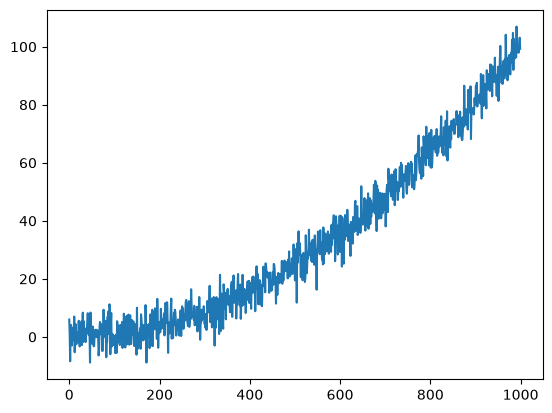

In [2]:
plot_model(model)

### Декомпозиція (STL)
Розкладаємо ряд на трендову, сезонну та залишкову складові.

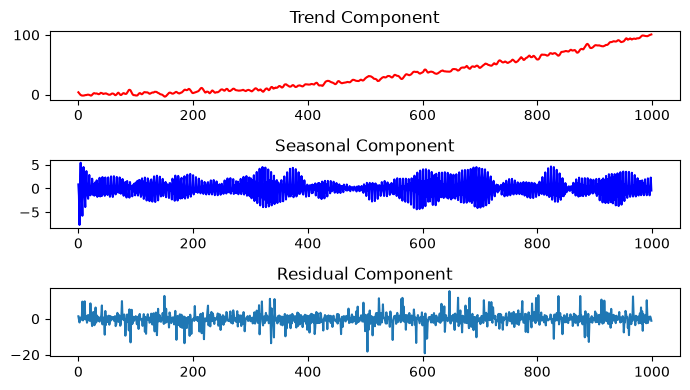

In [3]:
from time_series_analysis.decomposition import *
dcmpsd = decompose(model, 5, 11, True)
plot_decomposition(dcmpsd)

### Статистичні характеристики
Характеристики рахуються для залишків після видалення поліноміального тренду (МНК, 4-й степінь).

In [4]:
from time_series_analysis.stat_analysis import ts_stat_characteristics, dfuller_test_1, Sliding_Window_AV_Detect_medium

test
кількість елементів вбірки= 1000
матиматичне сподівання ВВ= -0.05694360428442735
дисперсія ВВ = 16.717123639821104
СКВ ВВ= 4.088657926486527 



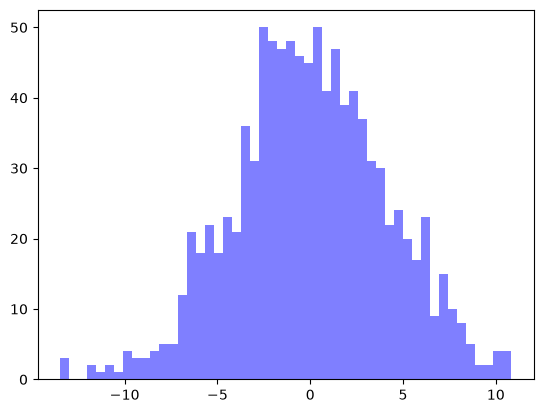

In [5]:
ts_stat_characteristics(model, "test")

### Тест Дікі-Фуллера на стаціонарність

Results of Dickey-Fuller Test_1:
ADF Statistic: 4.604829616268913
p-value: 1.0
Critical Values:
   1%: -3.43706091543889
   5%: -2.8645028204932483
   10%: -2.568347558984588


/home/budulka/Documents/TimeSeriesLabs/lab4/time_series_analysis/stat_analysis.py:69: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series)


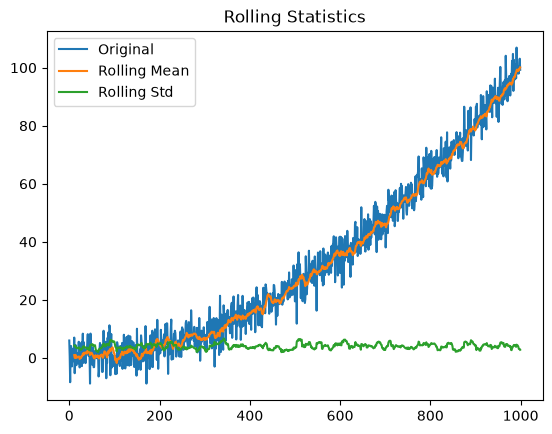

In [6]:
dfuller_test_1(model)

p-value = 1.0: ряд нестаціонарний, що очікувано через квадратичний тренд.

### Кластеризація (KMeans)
Кількість кластерів обираємо методом ліктя.

In [7]:
from time_series_analysis.clusterize import run_clustering, plot_elbow

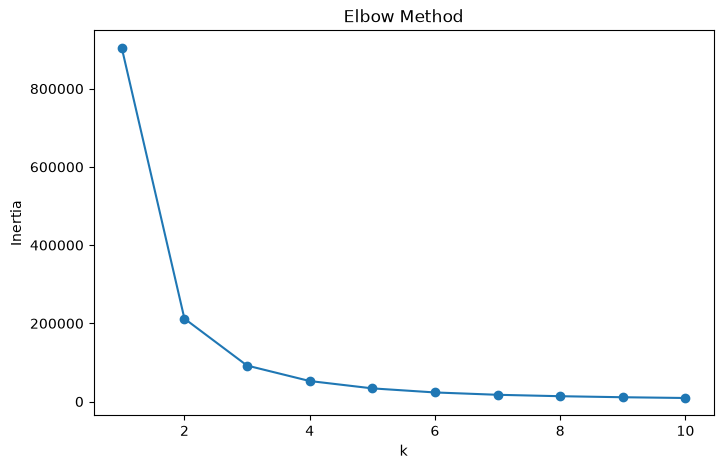

In [8]:
plot_elbow(model)

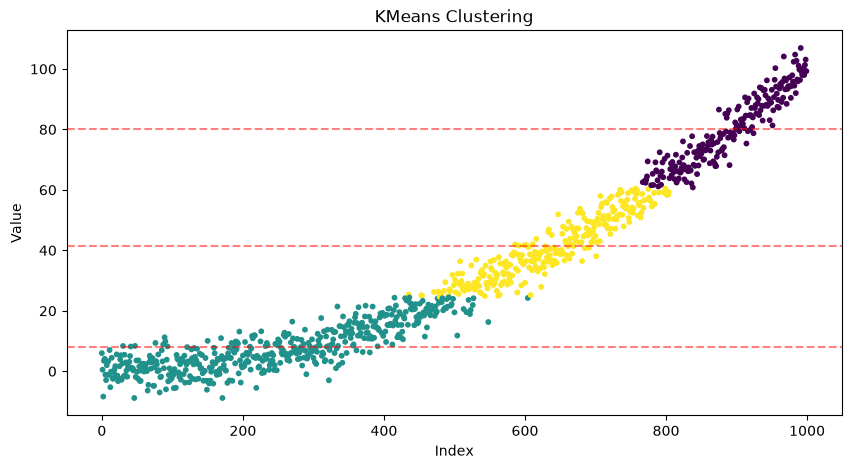

In [9]:
run_clustering(model, 3)

### Кореляційний аналіз
Кореляція та коваріація між компонентами декомпозиції.

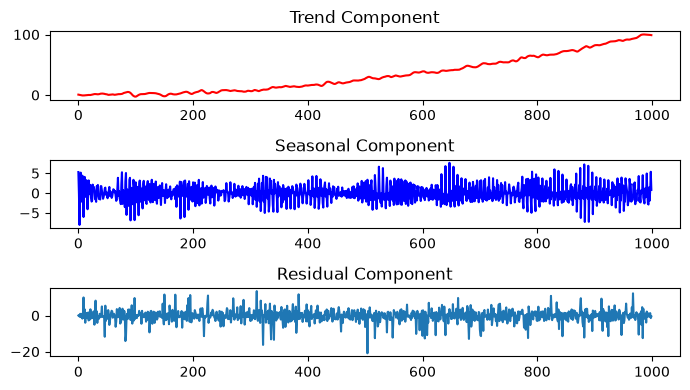

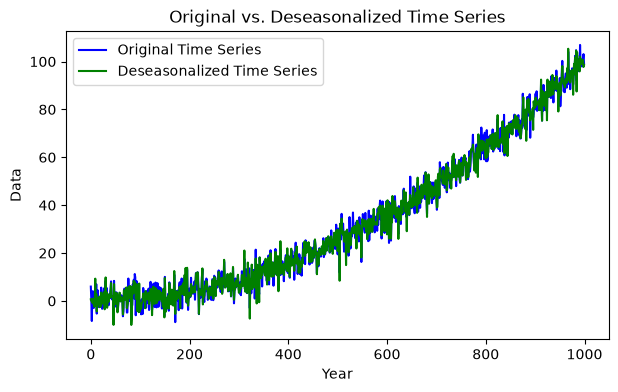

             trend  seasonal  residual  observed
trend     1.000000  0.002837 -0.039778  0.991582
seasonal  0.002837  1.000000 -0.130506  0.058981
residual -0.039778 -0.130506  1.000000  0.068810
observed  0.991582  0.058981  0.068810  1.000000
               trend  seasonal   residual    observed
trend     897.783407  0.182922  -4.222251  893.744077
seasonal    0.182922  4.629189  -0.994723    3.817388
residual   -4.222251 -0.994723  12.549811    7.332837
observed  893.744077  3.817388   7.332837  904.894302


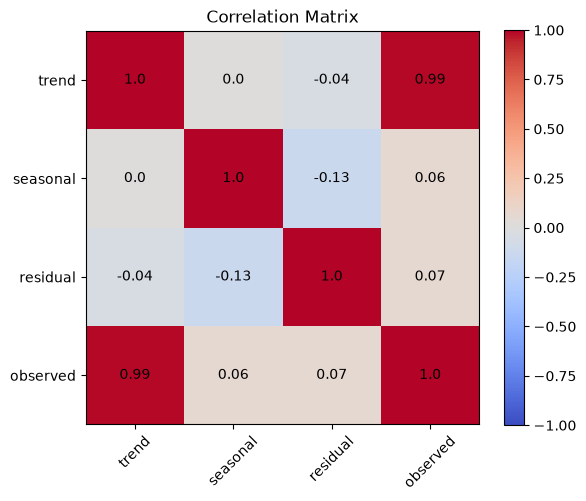

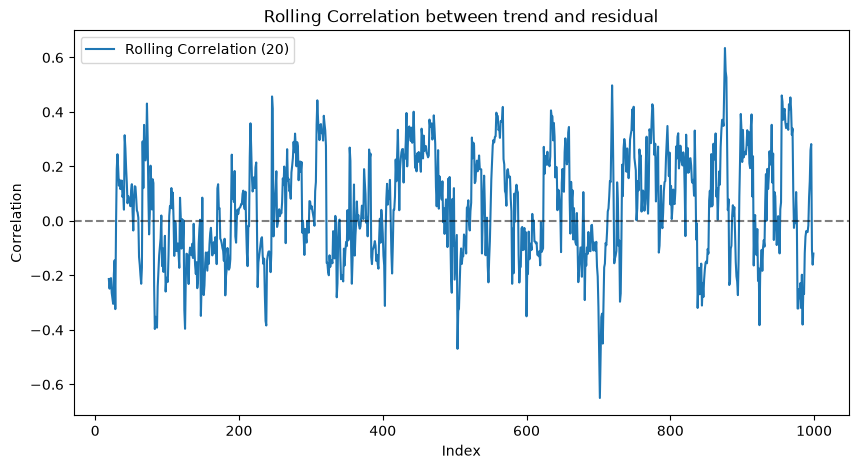

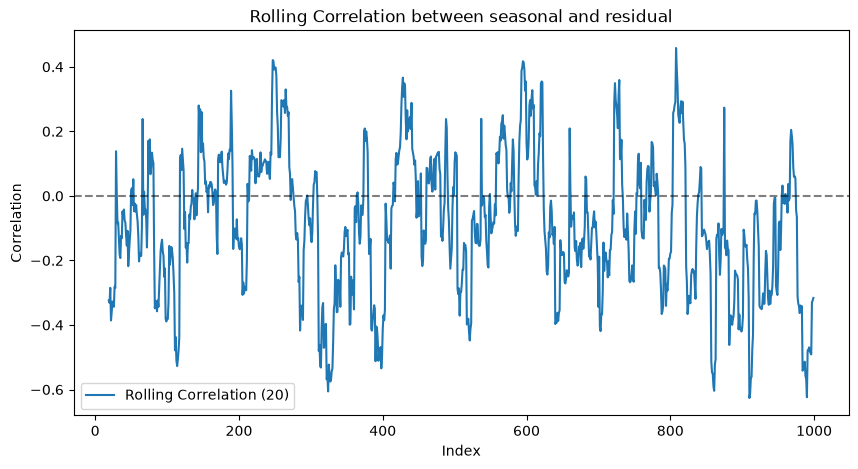

In [10]:
from time_series_analysis.correlation_analysis import run_correlation_analysis
run_correlation_analysis(model, 7)

### Висновки по синтетичних даних
Ряд нестаціонарний (p-value = 1.0), і його поведінку майже повністю визначає тренд: кореляція тренду з вихідним рядом 0.99. Сезонна і залишкова складові слабко пов'язані з трендом (|r| < 0.05), тобто шум адитивний і незалежний, як і закладено в модель. Кластеризація розбиває ряд на ділянки за рівнем значень, тобто фактично відображає етапи зростання тренду.

## Частина 2. Реальні дані: Data_Set_7.xlsx
Замовлення компанії за 2008–2009 роки, досліджуваний показник — виручка (`Revenue`).

In [11]:
import pandas as pd
df = pd.read_excel("Data_Set_7.xlsx", sheet_name=1)

In [12]:
df

,CustomerID,CustomerName,OrderDate,ProductName,EmployeeName,SupplierName,Paid?,CustomerCountry,CustomerState/Region,CustomerCity,UnitPrice,Quantity,Revenue
0,1090,Aakash Patel,2009-10-06,Tourtière,Janet Leverling,Ma Maison,Yes,Finland,NaN,Helsinki,7.45,60,447.0
1,1090,Aakash Patel,2009-03-10,Pavlova,Nancy Davolio,"Pavlova, Ltd.",Yes,Finland,NaN,Helsinki,13.90,35,486.5
2,1090,Aakash Patel,2008-10-01,Northwoods Cranberry Sauce,Margaret Peacock,Grandma Kelly's Homestead,Yes,Finland,NaN,Helsinki,32.00,70,2240.0
3,1090,Aakash Patel,2008-10-01,Chef Anton's Cajun Seasoning,Margaret Peacock,New Orleans Cajun Delights,Yes,Finland,NaN,Helsinki,17.60,35,616.0
4,1090,Aakash Patel,2009-04-10,Sirop d'érable,Margaret Peacock,Forêts d'érables,Yes,Finland,NaN,Helsinki,28.50,25,712.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2150,1054,Zachary McLeer,2009-04-24,Outback Lager,Janet Leverling,"Pavlova, Ltd.",Yes,Argentina,NaN,Buenos Aires,15.00,6,90.0
2151,1054,Zachary McLeer,2008-04-29,Outback Lager,Janet Leverling,"Pavlova, Ltd.",No,Argentina,NaN,Buenos Aires,15.00,3,45.0
2152,1054,Zachary McLeer,2009-04-24,Raclette Courdavault,Janet Leverling,Gai pâturage,Yes,Argentina,NaN,Buenos Aires,55.00,4,220.0
2153,1054,Zachary McLeer,2009-04-24,Filo Mix,Janet Leverling,"G'day, Mate",Yes,Argentina,NaN,Buenos Aires,7.00,6,42.0


Сортуємо замовлення за датою, щоб отримати часовий ряд.

In [13]:
df_sorted = df.sort_values(by='OrderDate').reset_index(drop=True)

In [14]:
Y = df_sorted['Revenue']

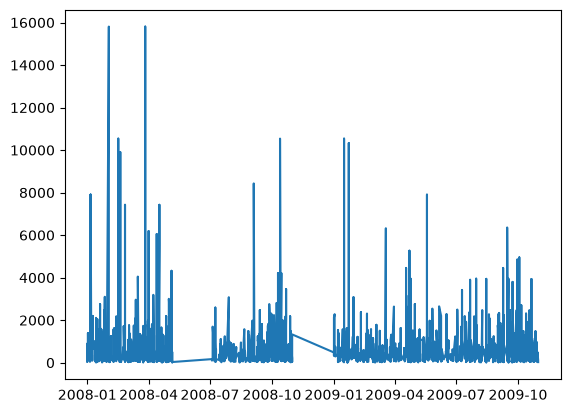

In [15]:
import matplotlib.pyplot as plt
plt.plot(df_sorted['OrderDate'], Y)

### Декомпозиція до і після очищення від аномалій

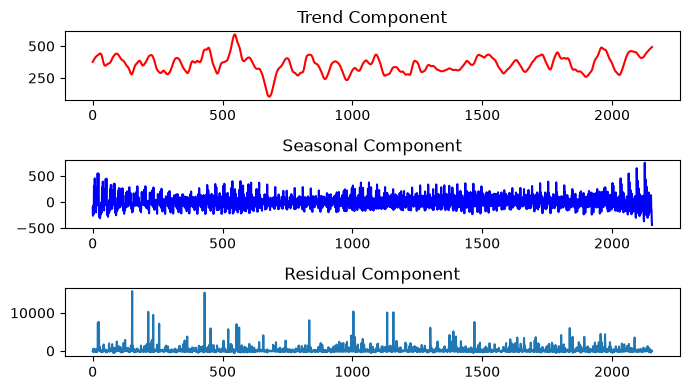

In [16]:
dcmpsd = decompose(Y, 31, 13, True)
plot_decomposition(dcmpsd)

In [17]:
cleaned = Sliding_Window_AV_Detect_medium(Y, 50, 1.1)

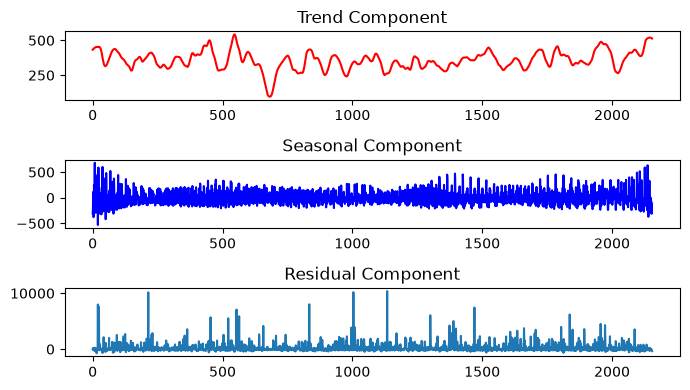

In [25]:
dcmpsd = decompose(cleaned, 30, 13, True)
plot_decomposition(dcmpsd)

### Статистичні характеристики і стаціонарність

test
кількість елементів вбірки= 2155
матиматичне сподівання ВВ= -246.02155569624415
дисперсія ВВ = 749465.4428619362
СКВ ВВ= 865.7167220644038 



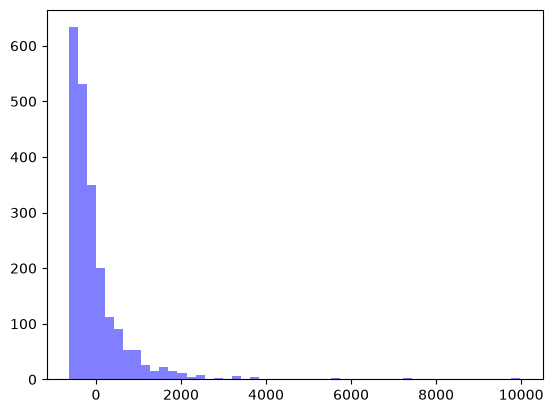

In [26]:
ts_stat_characteristics(Y, "test")

Results of Dickey-Fuller Test_1:
ADF Statistic: -42.693656711091556
p-value: 0.0
Critical Values:
   1%: -3.4333895125643408
   5%: -2.86288274571734
   10%: -2.567484811553121


/home/budulka/Documents/TimeSeriesLabs/lab4/time_series_analysis/stat_analysis.py:69: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series)


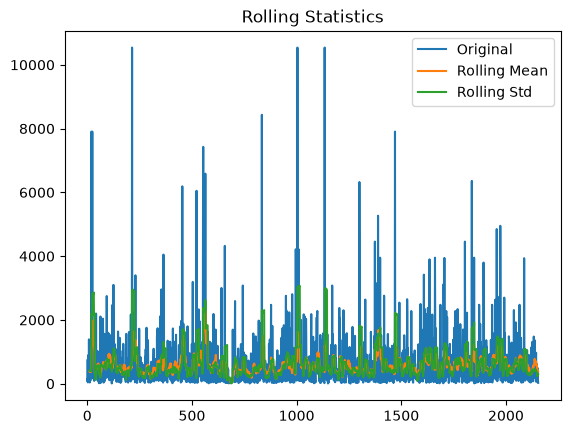

In [27]:
dfuller_test_1(Y)

### Кластеризація

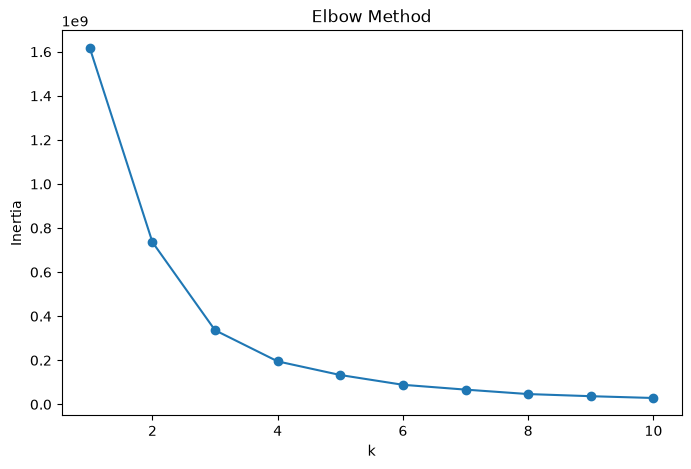

In [28]:
plot_elbow(Y)

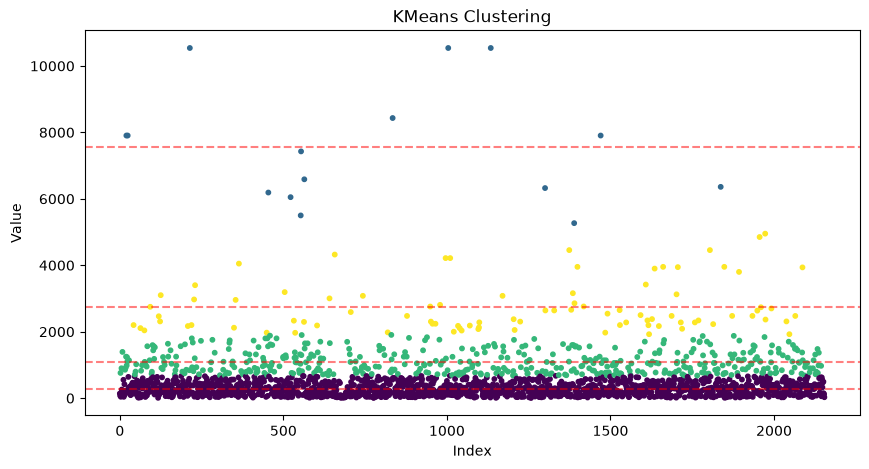

In [29]:
run_clustering(Y, 4)

### Кореляційний аналіз

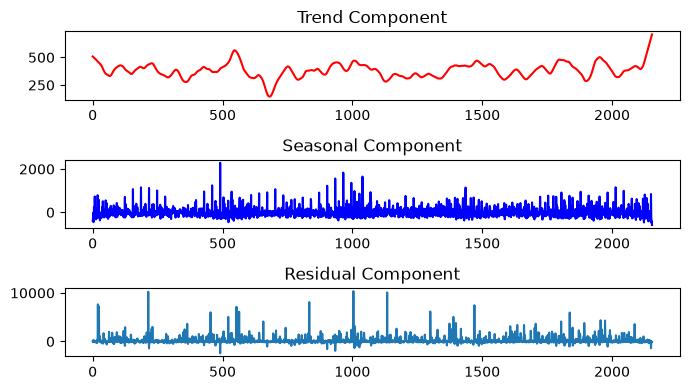

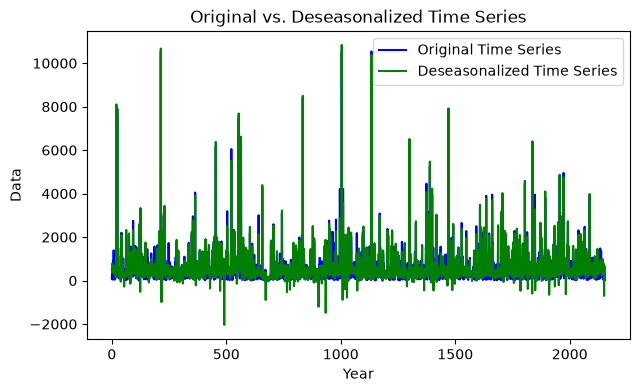

             trend  seasonal  residual  observed
trend     1.000000 -0.019834  0.056653  0.125952
seasonal -0.019834  1.000000 -0.057316  0.216834
residual  0.056653 -0.057316  1.000000  0.959197
observed  0.125952  0.216834  0.959197  1.000000
                trend      seasonal       residual       observed
trend     4382.192069   -311.687625    3153.905622    7224.410067
seasonal  -311.687625  56355.402631  -11442.503080   44601.211927
residual  3153.905622 -11442.503080  707226.980156  698938.382699
observed  7224.410067  44601.211927  698938.382699  750764.004692


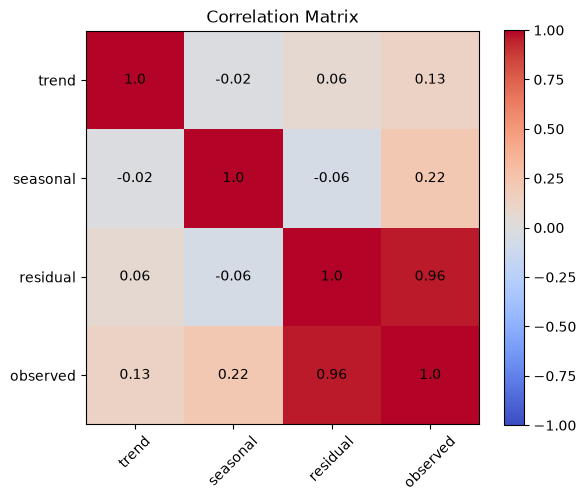

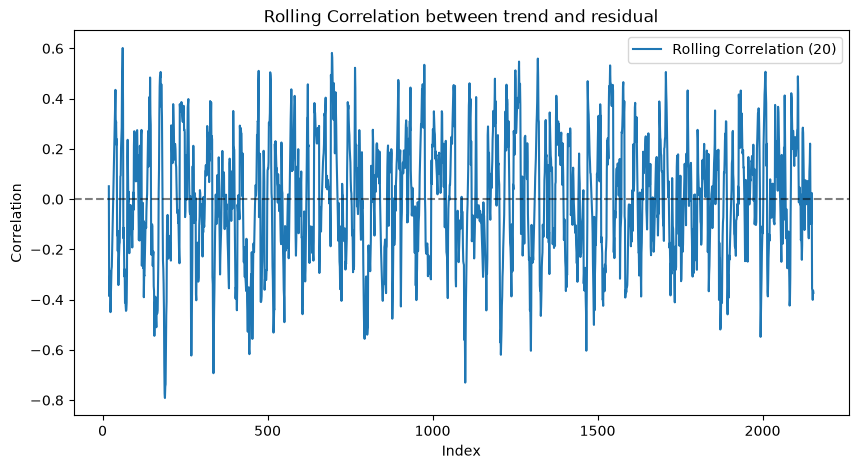

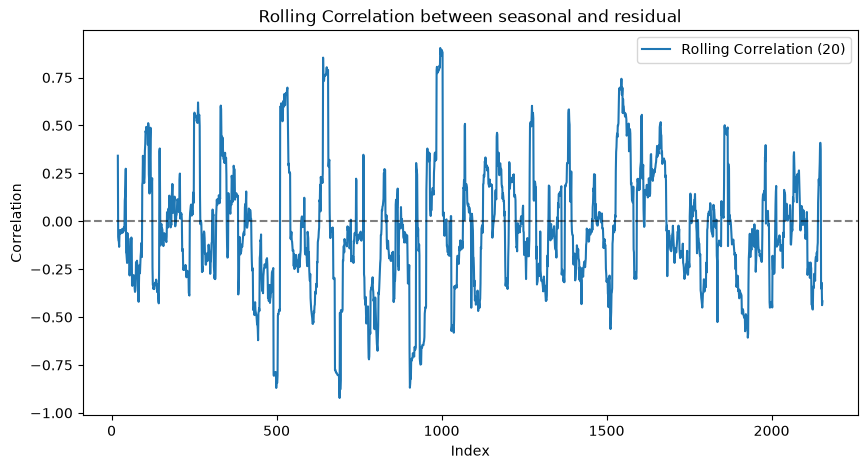

In [30]:
run_correlation_analysis(Y, 31)

## Висновки по реальних даних
Ряд виручки стаціонарний (ADF = −42.7, p-value ≈ 0) і не має вираженого тренду: трендова складова коливається в межах 250–500 без чіткого напрямку. Поведінку ряду визначає залишкова складова: її кореляція з вихідним рядом 0.96, а частка в загальній дисперсії ≈ 94%, і вона містить рідкісні великі замовлення (до 16 000). Кластеризація виділяє 4 групи замовлень за розміром: переважна більшість дрібні (до ~500), а великих угод небагато. У даних є періоди без замовлень (у середині та наприкінці 2008 року), що треба враховувати при моделюванні та прогнозуванні.

## Частина 3. Синтетична модель з властивостями реальних даних
Виявлені властивості Data_Set_7: усі значення додатні, розподіл сильно скошений, логарифм виручки розподілений майже нормально, ряд стаціонарний і без автокореляції. Тому модель така: log y(t) = лінійний тренд МНК + шум за скошеним нормальним законом. Функції винесено в модуль `synthetic_real_model.py`.

In [ ]:
from time_series_analysis.synthetic_real_model import fit_lognormal_model, generate_synthetic, compare_with_real, plot_real_vs_synthetic

real = df_sorted['Revenue'].to_numpy(dtype=float)
params = fit_lognormal_model(real, degree=1)
synthetic = generate_synthetic(params, len(real), seed=42)

Тренд log y(t), коефіцієнти МНК: [3.13583553e-05 5.75758148e+00]
Шум skew-normal: a=-1.191, loc=0.900, scale=1.472


### Порівняння характеристик
Статистики, стаціонарність (ADF), автокореляція і KS-тест для розподілів log y.

In [ ]:
comparison = compare_with_real(real, synthetic)
comparison.round(3)

KS-тест (розподіли log y): statistic=0.0269, p-value=0.4160
Розподіли статистично не відрізняються


,Реальні дані,Синтетична модель,"Відхилення, %"
середнє,628.519,641.788,2.111
медіана,360.000,343.580,-4.561
СКВ,1036.226,959.165,-7.437
мінімум,4.800,5.294,10.293
максимум,15810.000,17396.637,10.036
асиметрія,6.777,5.697,-15.941
середнє log,5.791,5.814,0.391
СКВ log,1.165,1.170,0.428
ACF(1),0.046,-0.007,NaN
ADF p-value,0.000,0.000,NaN


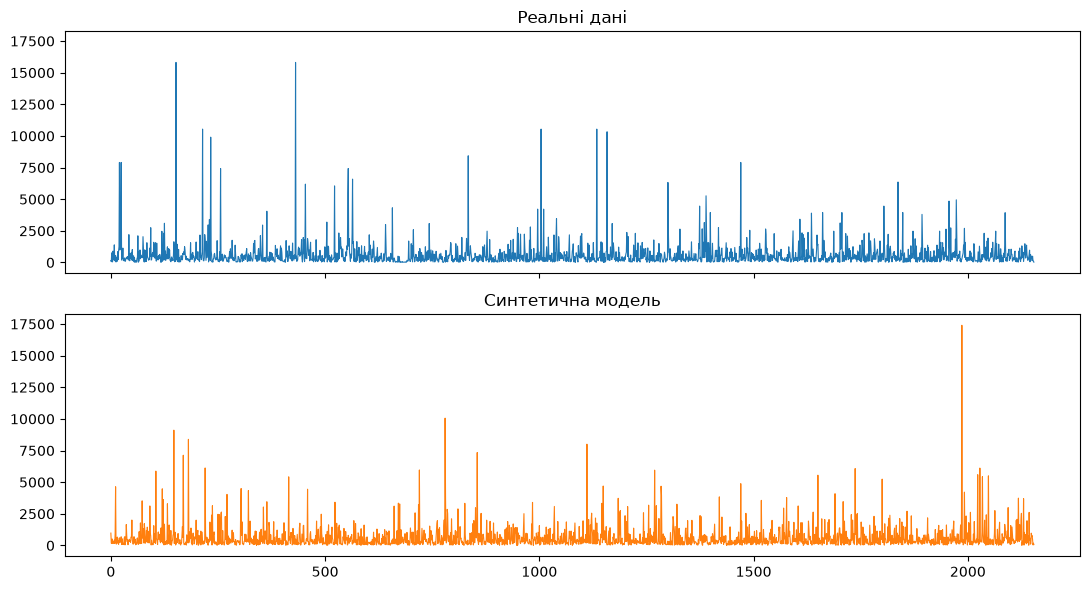

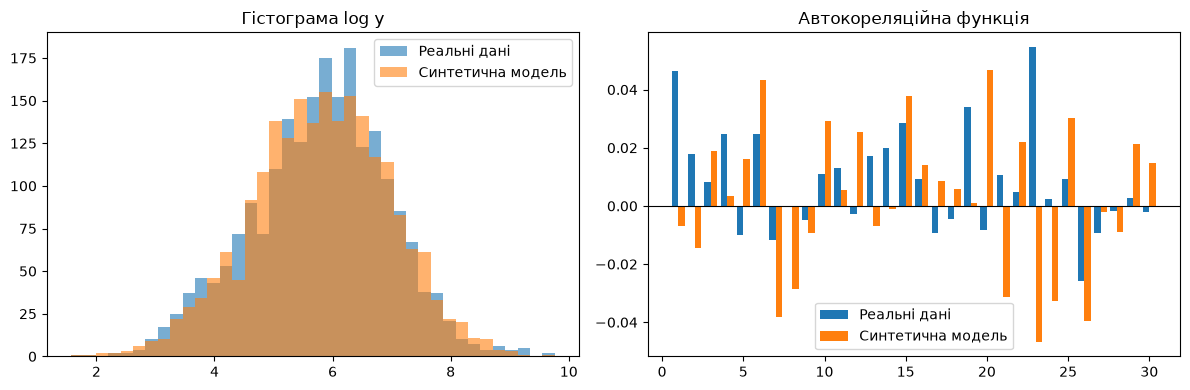

In [ ]:
plot_real_vs_synthetic(real, synthetic)

### Кластеризація синтетичного ряду
Перевіряємо, чи зберігається та сама структура груп замовлень, що й у реальних даних.

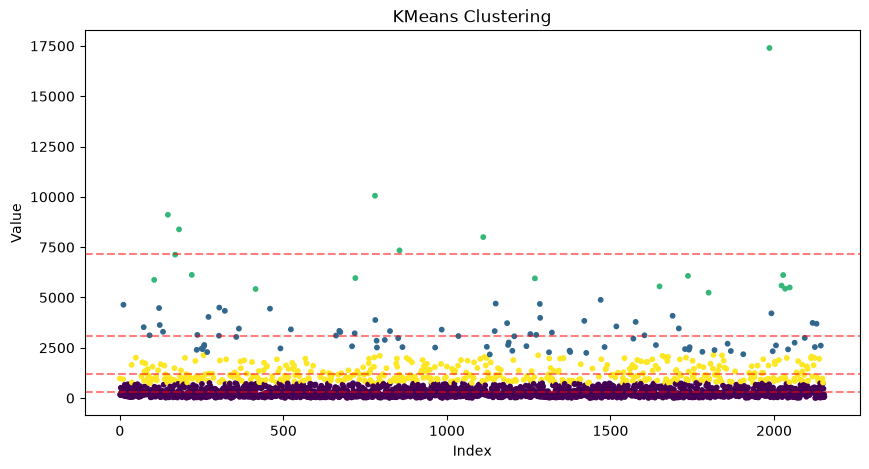

In [ ]:
run_clustering(synthetic, 4)

## Висновки щодо адекватності синтетичної моделі
Синтетична модель відтворює основні властивості реальних даних: середнє і медіана відрізняються менш ніж на 5%, СКВ — на 7%, а середнє і СКВ логарифма — менш ніж на 0.5%. KS-тест (p-value = 0.42) не виявив статистичної різниці між розподілами log y, і гістограми практично накладаються. Як і реальний, синтетичний ряд стаціонарний (ADF p-value = 0) і не має автокореляції (|ACF| < 0.06). Кластеризація дає ту саму структуру з 4 груп замовлень з близькими центрами. Менша асиметрія (−16%) пояснюється тим, що рідкісні дуже великі замовлення в одній реалізації моделі відтворюються випадково, тому загалом модель можна вважати адекватною.